# Bike rental demand prediction

Predict daily bike rentals using weather and calendar data.


### 1. Load data

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

In [4]:
df = pd.read_csv("day.csv")
print(df.shape)
df.head()

(731, 16)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### 2. Look at the data

In [5]:
print(df.columns)
print(df.info())
print(df.head(10))

Index(['instant', 'dteday', 'season', 'yr', 'mnth', 'holiday', 'weekday',
       'workingday', 'weathersit', 'temp', 'atemp', 'hum', 'windspeed',
       'casual', 'registered', 'cnt'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null   

In [6]:
print("Missing values:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values:
instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64
Duplicate rows: 0


In [7]:
print(df[["temp", "hum", "windspeed", "cnt"]].describe())

             temp         hum   windspeed          cnt
count  731.000000  731.000000  731.000000   731.000000
mean     0.495385    0.627894    0.190486  4504.348837
std      0.183051    0.142429    0.077498  1937.211452
min      0.059130    0.000000    0.022392    22.000000
25%      0.337083    0.520000    0.134950  3152.000000
50%      0.498333    0.626667    0.180975  4548.000000
75%      0.655417    0.730209    0.233214  5956.000000
max      0.861667    0.972500    0.507463  8714.000000


### 3. Clean the data

In [8]:
bike = df.copy()
bike = bike.drop_duplicates()
bike["dteday"] = pd.to_datetime(bike["dteday"], errors="coerce")
bike = bike.dropna(subset=["dteday", "cnt"])
bike = bike.sort_values("dteday")
print("Rows before:", len(df))
print("Rows after:", len(bike))

Rows before: 731
Rows after: 731


In [9]:
# UCI temperature, humidity and wind values are scaled (0 to 1)
print(bike[["temp", "hum", "windspeed", "cnt"]].isnull().sum())

temp         0
hum          0
windspeed    0
cnt          0
dtype: int64


### 4. Explore the data

**Q1. How did bike rentals change over time?**

dteday
2011-01    1231.903226
2011-02    1721.964286
2011-03    2065.967742
2011-04    3162.333333
2011-05    4381.322581
Freq: M, Name: cnt, dtype: float64


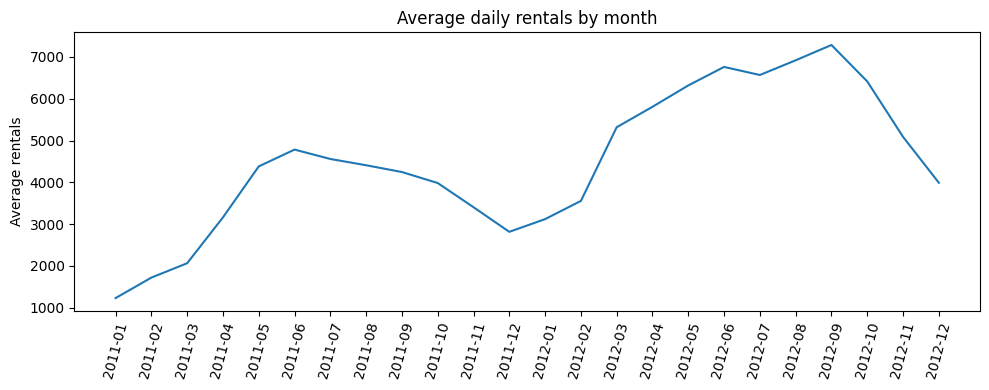

In [10]:
monthly = bike.groupby(bike["dteday"].dt.to_period("M"))["cnt"].mean()
print(monthly.head())
plt.figure(figsize=(10, 4))
plt.plot(monthly.index.astype(str), monthly.values)
plt.title("Average daily rentals by month")
plt.ylabel("Average rentals")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

**Q2. Which season had the most rentals?**

season
1    2604.132597
2    4992.331522
3    5644.303191
4    4728.162921
Name: cnt, dtype: float64


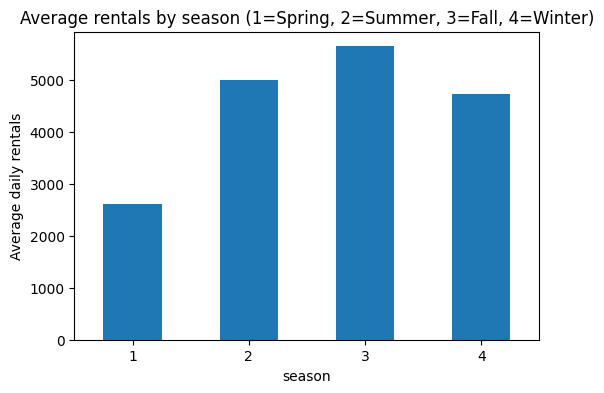

In [11]:
season_sales = bike.groupby("season")["cnt"].mean()
print(season_sales)
season_sales.plot(kind="bar", figsize=(6, 4))
plt.title("Average rentals by season (1=Spring, 2=Summer, 3=Fall, 4=Winter)")
plt.ylabel("Average daily rentals")
plt.xticks(rotation=0)
plt.show()

**Q3. Do working days have different rental demand?**

workingday
0    4330.168831
1    4584.820000
Name: cnt, dtype: float64


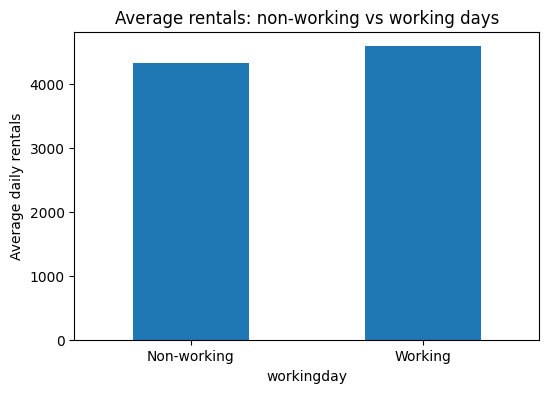

In [12]:
workday = bike.groupby("workingday")["cnt"].mean()
print(workday)
workday.plot(kind="bar", figsize=(6, 4))
plt.title("Average rentals: non-working vs working days")
plt.ylabel("Average daily rentals")
plt.xticks([0, 1], ["Non-working", "Working"], rotation=0)
plt.show()

### 5. Choose features

In [13]:
# cnt is the number of total rentals (our target)
# casual and registered are excluded because casual + registered = cnt
features = ["season", "yr", "mnth", "holiday", "weekday", "workingday",
            "weathersit", "temp", "atemp", "hum", "windspeed"]
X = bike[features]
y = bike["cnt"]
print(X.shape)
X.head()

(731, 11)


,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed
0,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446
1,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539
2,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309
3,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296
4,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900


### 6. Split the data

In [14]:
# Train on earlier dates, test on later dates
split = int(len(bike) * 0.8)
X_train = X.iloc[:split]
X_test = X.iloc[split:]
y_train = y.iloc[:split]
y_test = y.iloc[split:]
print("Training days:", len(X_train))
print("Testing days:", len(X_test))

Training days: 584
Testing days: 147


### 7. Train models

**Model 1: Linear Regression**

In [15]:
linear = LinearRegression()
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, linear_pred), 2))
print("R2:", round(r2_score(y_test, linear_pred), 3))

MAE: 863.86
R2: 0.613


**Model 2: Decision Tree**

In [16]:
tree = DecisionTreeRegressor(max_depth=5, random_state=42)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, tree_pred), 2))
print("R2:", round(r2_score(y_test, tree_pred), 3))

MAE: 954.69
R2: 0.585


**Model 3: Random Forest**

In [17]:
forest = RandomForestRegressor(n_estimators=100, max_depth=7, random_state=42)
forest.fit(X_train, y_train)
forest_pred = forest.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, forest_pred), 2))
print("R2:", round(r2_score(y_test, forest_pred), 3))

MAE: 926.8
R2: 0.646


### 8. Compare models

In [18]:
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "MAE": [mean_absolute_error(y_test, linear_pred),
            mean_absolute_error(y_test, tree_pred),
            mean_absolute_error(y_test, forest_pred)],
    "R2": [r2_score(y_test, linear_pred),
           r2_score(y_test, tree_pred),
           r2_score(y_test, forest_pred)]
})
print(results.round(2))

               Model     MAE    R2
0  Linear Regression  863.86  0.61
1      Decision Tree  954.69  0.58
2      Random Forest  926.80  0.65


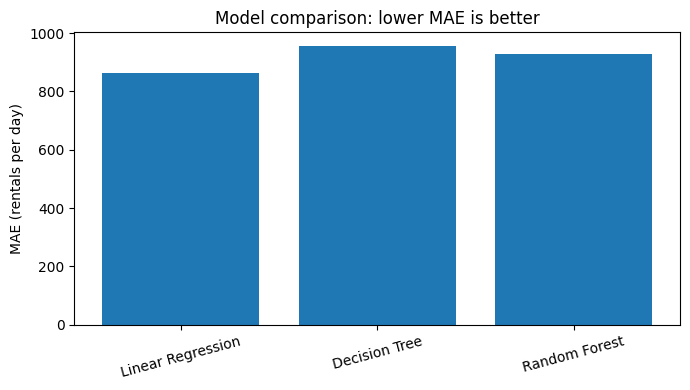

In [19]:
plt.figure(figsize=(7, 4))
plt.bar(results["Model"], results["MAE"])
plt.title("Model comparison: lower MAE is better")
plt.ylabel("MAE (rentals per day)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Q4. How close are the predictions to actual rentals?**

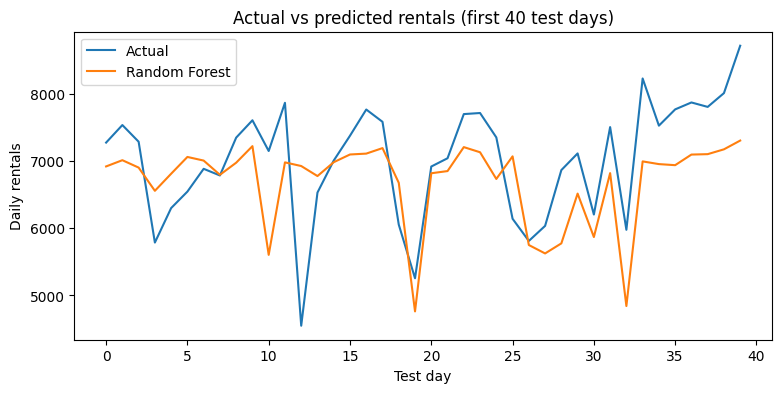

In [20]:
plt.figure(figsize=(9, 4))
plt.plot(y_test.values[:40], label="Actual")
plt.plot(forest_pred[:40], label="Random Forest")
plt.title("Actual vs predicted rentals (first 40 test days)")
plt.xlabel("Test day")
plt.ylabel("Daily rentals")
plt.legend()
plt.show()

**Q5. Which features mattered most in Random Forest?**

temp         0.305204
atemp        0.263174
yr           0.255398
hum          0.056099
season       0.044817
windspeed    0.022173
dtype: float64


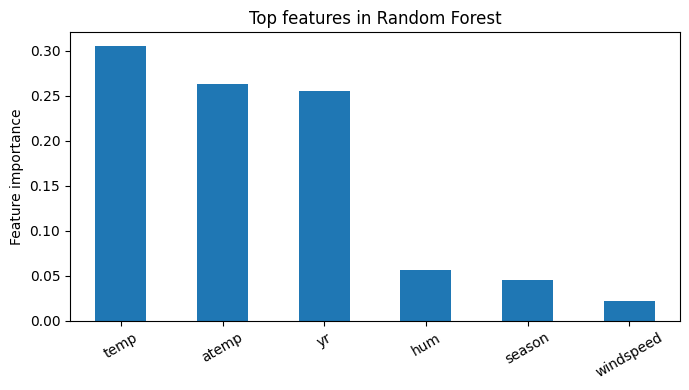

In [21]:
importance = pd.Series(forest.feature_importances_, index=features)
importance = importance.sort_values(ascending=False)
print(importance.head(6))
importance.head(6).plot(kind="bar", figsize=(7, 4))
plt.title("Top features in Random Forest")
plt.ylabel("Feature importance")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

### 9. What I found

In [22]:
best = results.loc[results["MAE"].idxmin()]
print("Best model:", best["Model"])
print("Test MAE:", round(best["MAE"], 2), "rentals per day")
print("Highest rental season:", season_sales.idxmax())
print("Working day average:", round(workday.loc[1], 0))
print("Non-working day average:", round(workday.loc[0], 0))


Best model: Linear Regression
Test MAE: 863.86 rentals per day
Highest rental season: 3
Working day average: 4585.0
Non-working day average: 4330.0
